In [1]:
# Set Up Library
# Library untuk PATH
from pathlib import Path

# Library FFMPEG dan progress bar (folder and files management)
import subprocess
from tqdm import tqdm
import shutil
import os

# Library base
import numpy as np
import time

# Library dataset, model, dan evaluasi
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

# Library visualisasi grafik
import seaborn as sns
import matplotlib.pyplot as plt

**Dataset Merging**

In [10]:
# Read PATH pose sequences dataset kinetics dan dataset self-recorded
pose_seq1 = Path('pose_sequences_kinetics')
pose_seq2 = Path('pose_sequences_self')

In [11]:
# Setup output folder sekuens pose untuk gabungan kedua dataset
pose_seq_combined = Path('pose_sequences')
pose_seq_combined.mkdir(exist_ok=True)

In [13]:
# Menggabungkan (merge) sekuens pose dari kedua dataset
classes = set([d.name for d in pose_seq1.iterdir() if d.is_dir()] +
              [d.name for d in pose_seq2.iterdir() if d.is_dir()])

for cls in classes:
  out_dir = pose_seq_combined / cls
  out_dir.mkdir(exist_ok=True)

  # dari kinetics
  src1 = pose_seq1 / cls
  if src1.exists():
    for file in src1.iterdir():
      if file.is_file():
        new_name = file.name
        shutil.copy(file, out_dir / new_name)

  # dari self record
  src2 = pose_seq2 / cls
  if src2.exists():
    for file in src2.iterdir():
      if file.is_file():
        new_name = file.name
        shutil.copy(file, out_dir / new_name)

print("Merging sekuens pose dari kedua dataset selesai")

Merging sekuens pose dari kedua dataset selesai


### **Data Normalization and Feature Extraction**

**1: Sequence Normalization**

In [14]:
# Fungsi max frame length untuk meringkas informasi sekuens pose
def fix_seq_length(seq, target_len=120):
  """
  Jika lebih dari 120: Uniform Sampling
  Jika kurang dari 120: Post-Padding
  """

  real_len = len(seq)

  if real_len >= target_len:
    idx = np.linspace(0, real_len-1, target_len).astype(int)
    return seq[idx], target_len
  else:
    pad_len = target_len - real_len
    pad = np.zeros((pad_len, seq.shape[1], seq.shape[2]))
    seq_fixed = np.concatenate([seq, pad], axis=0)
  
  return seq_fixed, real_len

In [15]:
# Fungsi menghitung sudut sendi (menjadi fitur yang masuk ke model)
def calculate_joint_angles(A, B, C):
  ba = A - B
  bc = C - B
  
  cosine = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-6)
  angle = np.arccos(np.clip(cosine, -1.0, 1.0))
  return angle

In [16]:
# Fungsi normalisasi pose dengan menggeser semua titik pose relatif terhadap titik pusat tubuh
def normalize_pose(seq):
  center = seq[:, 23:24, :]
  seq = seq - center

  shoulder_dist = np.linalg.norm(seq[:, 11] - seq[:, 12], axis=1, keepdims=True)
  shoulder_dist[shoulder_dist == 0] = 1

  seq = seq / shoulder_dist[:, None, :]
  return seq

In [17]:
# Label kelas workout menjadi numerikal
label_map = {
  "jumping_jacks": 0,
  "squat": 1,
  "mountain_climber": 2,
  "knee_push_up": 3,
  "sit_up": 4
}

In [18]:
# body landmark indeks (dari mediapipe pose landmarker)
# badan
LEFT_HIP = 23
RIGHT_HIP = 24

# limbs bagian atas
LEFT_SHOULDER = 11
RIGHT_SHOULDER = 12
LEFT_ELBOW = 13
RIGHT_ELBOW = 14
LEFT_WRIST = 15
RIGHT_WRIST = 16

# limbs bagian bawah
LEFT_KNEE = 25
RIGHT_KNEE = 26
LEFT_ANKLE = 27
RIGHT_ANKLE = 28

In [19]:
# Fungsi ekstraksi sudut sendi untuk fitur
def extract_joint_angles(seq):
  angles_all = []

  for frame in seq: 
    angles = []

    # siku kiri kanan
    angles.append(calculate_joint_angles(frame[LEFT_SHOULDER], frame[LEFT_ELBOW], frame[LEFT_WRIST]))
    angles.append(calculate_joint_angles(frame[RIGHT_SHOULDER], frame[RIGHT_ELBOW], frame[RIGHT_WRIST]))

    # lutut kiri kanan
    angles.append(calculate_joint_angles(frame[LEFT_HIP], frame[LEFT_KNEE], frame[LEFT_ANKLE]))
    angles.append(calculate_joint_angles(frame[RIGHT_HIP], frame[RIGHT_KNEE], frame[RIGHT_ANKLE]))

    # pinggul (hip) kiri kanan
    angles.append(calculate_joint_angles(frame[LEFT_SHOULDER], frame[LEFT_HIP], frame[LEFT_KNEE]))
    angles.append(calculate_joint_angles(frame[RIGHT_SHOULDER], frame[RIGHT_HIP], frame[RIGHT_KNEE]))

    angles_all.append(angles)

  return np.array(angles_all)

In [20]:
# Fungsi velocity
def extract_velocity(seq):
  vel = np.diff(seq, axis=0, prepend=seq[:1])
  return vel

In [21]:
# Fungsi extract foot asymmetry (khusus untuk gerakan mountain climber vs push up)
def extract_foot_asymmetry(seq, vel):
  """
  seq: (T, 33, 3) sudah ternormalisasi
  vel: (T, 33, 3) velocity yang sudah dihitung sebelumnya
  """

  left_foot_vel = vel[:, LEFT_ANKLE, :]   
  right_foot_vel = vel[:, RIGHT_ANKLE, :]
  asymmetry = left_foot_vel - right_foot_vel  
    
  hip_center = (seq[:, 23] + seq[:, 24]) / 2
  hip_vel_y = np.diff(hip_center[:, 1], prepend=hip_center[0, 1])[:, np.newaxis] 
    
  return asymmetry, hip_vel_y

In [22]:
# Fungsi extraksi orientasi torso (membedakan pose tegak (vertikal) dan horizontal)
def extract_torso_orientation(seq):
  shoulder_vec = seq[:, RIGHT_SHOULDER, :] - seq[:, LEFT_SHOULDER, :]
  
  hip_vec = seq[:, RIGHT_HIP, :] - seq[:, LEFT_HIP, :]

  shoulder_mid = (seq[:, LEFT_SHOULDER, :] + seq[:, RIGHT_SHOULDER, :]) / 2
  hip_mid = (seq[:, LEFT_HIP, :] + seq[:, RIGHT_HIP, :]) / 2
  torso_vec = shoulder_mid - hip_mid

  return np.concatenate([shoulder_vec, hip_vec, torso_vec], axis=-1)

In [23]:
# Read PATH pose sequences hasil merging
pose_seq_merged = Path("pose_sequences")

In [24]:
X_input_fitur = []
X_input_3d = []
X_lengths = []
Y_label_target = []

for class_name, label in label_map.items():
  class_dir = pose_seq_merged / class_name

  for file in class_dir.glob("*.npy"):
    seq = np.load(file)
    if len(seq) < 10:
      continue
    
    seq = normalize_pose(seq)
    seq, real_len = fix_seq_length(seq)

    vel_3d = extract_velocity(seq)
    angles = extract_joint_angles(seq)
    vel_flat = vel_3d.reshape(120, -1)
    foot_asym, hip_vel = extract_foot_asymmetry(seq, vel_3d)
    torso = extract_torso_orientation(seq)
    seq_flat = seq.reshape(seq.shape[0], -1)

    combined_features = np.concatenate([
      seq_flat, 
      angles, 
      vel_flat, 
      foot_asym, 
      hip_vel,
      torso
      ], axis=1)

    X_input_fitur.append(combined_features)
    X_input_3d.append(seq)
    X_lengths.append(real_len)
    Y_label_target.append(label)

In [25]:
# Melihat total data yang berhasil dipraproses
print("Total data sekuens pose final:", len(X_input_fitur))
print("Shape sample pada sekuens pose:", X_input_fitur[0].shape)

if np.isnan(np.array(X_input_fitur)).any():
    print("Terdapat nilai NaN")
else:
    print("Nilai aman, tidak ada NaN")

Total data sekuens pose final: 1745
Shape sample pada sekuens pose: (120, 217)
Nilai aman, tidak ada NaN


### **Data Transformation**

**2: Dataset Split and Transformation to Tensor**

In [26]:
# Dataset split ke training-validation-test
(X_train_val, X_test, 
 X_train_val_3d, X_test_3d, 
 lengths_train_val, lengths_test, 
 y_train_val, y_test) = train_test_split(
  X_input_fitur, X_input_3d, X_lengths, Y_label_target,
  test_size=0.2,
  stratify=Y_label_target,
  random_state=42
)

(X_train, X_val,
 X_train_3d, X_val_3d,
 lengths_train, lengths_val,
  y_train, y_val) = train_test_split(
  X_train_val, X_train_val_3d, lengths_train_val, y_train_val,
  test_size=0.125,
  stratify=y_train_val,
  random_state=42
)

In [27]:
# Fungsi untuk augmentasi data: holizontal flip, temporal scaling, dan gaussian noise
FLIP_PAIRS = [(11,12),(13,14),(15,16),(23,24),(25,26),(27,28),(29,30),(31,32)]

def horizontal_flip_seq(seq_3d):
    flipped = seq_3d.copy()
    flipped[:, :, 0] = -flipped[:, :, 0]
    for l, r in FLIP_PAIRS:
        flipped[:, [l, r]] = flipped[:, [r, l]]
    return flipped

def rebuild_features(seq_3d):
    """Re-extract semua fitur dari seq_3d"""
    vel_3d    = extract_velocity(seq_3d)
    angles    = extract_joint_angles(seq_3d)
    vel_flat  = vel_3d.reshape(120, -1)
    foot_asym, hip_vel = extract_foot_asymmetry(seq_3d, vel_3d)
    torso     = extract_torso_orientation(seq_3d)
    seq_flat  = seq_3d.reshape(seq_3d.shape[0], -1)
    return np.concatenate([seq_flat, angles, vel_flat, foot_asym, hip_vel, torso], axis=1)

def temporal_scaling_aug(seq, target_len=120):
  delta = np.random.randint(-15, 16)
  new_length = max(10, target_len + delta)

  idx = np.linspace(0, len(seq)-1, new_length).astype(int)
  seq_scaled = seq[idx]

  idx2 = np.linspace(0, len(seq_scaled)-1, target_len).astype(int)
  return seq_scaled[idx2]

def gaussian_noise_aug(seq, std=0.01):
  return seq + np.random.normal(0, std, seq.shape).astype(np.float32)

In [28]:
# Augmentasi data training
X_train_aug = []
lengths_train_aug = []
y_train_aug = []

for seq, seq_3d, length, label in zip(X_train, X_train_3d, lengths_train, y_train):
    # 1. Original
    X_train_aug.append(seq)
    lengths_train_aug.append(length)
    y_train_aug.append(label)

    # 2. Temporal scaling
    X_train_aug.append(temporal_scaling_aug(seq))
    lengths_train_aug.append(length)
    y_train_aug.append(label)

    # 3. Gaussian noise
    X_train_aug.append(gaussian_noise_aug(seq))
    lengths_train_aug.append(length)
    y_train_aug.append(label)

    # 4. Horizontal flip
    flipped_3d = horizontal_flip_seq(seq_3d)
    X_train_aug.append(rebuild_features(flipped_3d))
    lengths_train_aug.append(length)
    y_train_aug.append(label)

X_train        = np.array(X_train_aug)
lengths_train  = np.array(lengths_train_aug)
y_train        = np.array(y_train_aug)

In [29]:
# Konversi ke PyTorch Tensor
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

C:\Users\lenovo\AppData\Local\Temp\ipykernel_22944\4007888984.py:5: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\cb\pytorch_1000000000000\work\torch\csrc\utils\tensor_new.cpp:281.)
  X_val_tensor = torch.tensor(X_val, dtype=torch.float32)


In [30]:
# Mengecek apakah ada sekuens aneh atau tidak
print("Train (augmented) tensor shape:", X_train_tensor.shape)
print("Val tensor shape:", X_val_tensor.shape)
print("Test tensor shape:", X_test_tensor.shape, "\n")

# Mengecek distribusi label
unique, counts = np.unique(y_train_tensor.numpy(), return_counts=True)
print(f"Distribusi label: {dict(zip(unique, counts))}")

Train (augmented) tensor shape: torch.Size([4884, 120, 217])
Val tensor shape: torch.Size([175, 120, 217])
Test tensor shape: torch.Size([349, 120, 217]) 

Distribusi label: {np.int64(0): np.int64(1028), np.int64(1): np.int64(1028), np.int64(2): np.int64(1028), np.int64(3): np.int64(940), np.int64(4): np.int64(860)}


In [31]:
# Load tensor ke DataLoader
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(lengths_train, dtype=torch.long),
        torch.tensor(y_train, dtype=torch.long)
    ),
    batch_size=32, shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(np.array(lengths_val), dtype=torch.long),
        torch.tensor(y_val, dtype=torch.long)
    ),
    batch_size=32
)

test_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(np.array(lengths_test), dtype=torch.long),
        torch.tensor(y_test, dtype=torch.long)
    ),
    batch_size=32
)

### **Model Architecture (Attention LSTM) and Training**

**3: Define Architecture Model (Attention LSTM with Spatial and Temporal Attention)**

In [4]:
# Mendefinisikan model Attention LSTM yang dikembangkan
class SpatialTemporalAttentionLSTM(nn.Module):
    def __init__(self, input_size=217, hidden_size=128, num_classes=5):
        super().__init__()

        self.spatial_attn = nn.Linear(input_size, input_size)

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.3
        )

        self.norm = nn.LayerNorm(hidden_size)

        self.temporal_attn = nn.Linear(hidden_size, 1)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x, lengths):
        mask = torch.arange(x.size(1), device=x.device)[None, :] < lengths[:, None]

        spatial_weights = torch.softmax(self.spatial_attn(x), dim=-1)
        x = x * spatial_weights

        x = x * mask.unsqueeze(-1).float()

        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        lstm_out, _ = self.lstm(packed)
        lstm_out, _ = pad_packed_sequence(lstm_out, batch_first=True, total_length=x.size(1))
        lstm_out = self.norm(lstm_out)

        attn_scores = self.temporal_attn(lstm_out).squeeze(-1)
        attn_scores = attn_scores.masked_fill(~mask, float('-inf'))
        temporal_weights = torch.softmax(attn_scores, dim=1)
        
        context = torch.sum(lstm_out * temporal_weights.unsqueeze(-1), dim=1)

        return self.classifier(context)

In [5]:
# Inisialisasi model agar menggunakan GPU saat training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} \n")
print(f"GPU: {torch.cuda.get_device_name(0)} \n")

Attn_LSTM_model = SpatialTemporalAttentionLSTM().to(device)
print(Attn_LSTM_model)

Device: cuda 

GPU: NVIDIA GeForce RTX 4060 Laptop GPU 

SpatialTemporalAttentionLSTM(
  (spatial_attn): Linear(in_features=217, out_features=217, bias=True)
  (lstm): LSTM(217, 128, num_layers=2, batch_first=True, dropout=0.3)
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (temporal_attn): Linear(in_features=128, out_features=1, bias=True)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=5, bias=True)
  )
)


In [38]:
# Loss & Optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(Attn_LSTM_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=10
)

**4: Training Model with Early Stopping**

In [39]:
# Training Model
num_epochs = 100

train_losses = []
val_losses = []

best_val_loss = float('inf')
patience = 15
counter = 0

for epoch in range(num_epochs):
  Attn_LSTM_model.train()
  total_train_loss = 0

  for X_batch, lengths_batch, y_batch in train_loader:
    X_batch = X_batch.to(device)
    lengths_batch = lengths_batch.to(device)
    y_batch = y_batch.to(device)

    optimizer.zero_grad()
    outputs = Attn_LSTM_model(X_batch, lengths_batch)
    loss = criterion(outputs, y_batch)
    loss.backward()
    optimizer.step()

    total_train_loss += loss.item()

  avg_train_loss = total_train_loss / len(train_loader)
  train_losses.append(avg_train_loss)

  # validation
  Attn_LSTM_model.eval()
  total_val_loss = 0

  with torch.no_grad():
    for X_batch, lengths_batch, y_batch in val_loader:
      X_batch = X_batch.to(device)
      lengths_batch = lengths_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = Attn_LSTM_model(X_batch, lengths_batch)
      loss = criterion(outputs, y_batch)

      total_val_loss += loss.item()
  
  avg_val_loss = total_val_loss / len(val_loader)
  val_losses.append(avg_val_loss)

  scheduler.step(avg_val_loss)

  current_lr = optimizer.param_groups[0]['lr']

  print(f"Epoch {epoch+1}/{num_epochs} | Train loss: {avg_train_loss:.4f} | Val loss: {avg_val_loss:.4f} | "
        f"LR: {current_lr:.6f}")

  # Early stopping 
  if avg_val_loss < best_val_loss:
    best_val_loss = avg_val_loss
    counter = 0
    torch.save(Attn_LSTM_model.state_dict(), "best_attn_lstm_model.pth")
  else:
    counter += 1

  if counter >= patience:
    print(f"Early stopping pada epoch {epoch+1}")
    break

Epoch 1/100 | Train loss: 0.0279 | Val loss: 0.2113 | LR: 0.001000
Epoch 2/100 | Train loss: 0.0381 | Val loss: 0.0588 | LR: 0.001000
Epoch 3/100 | Train loss: 0.0184 | Val loss: 0.1701 | LR: 0.001000
Epoch 4/100 | Train loss: 0.0296 | Val loss: 0.1021 | LR: 0.001000
Epoch 5/100 | Train loss: 0.0081 | Val loss: 0.1705 | LR: 0.001000
Epoch 6/100 | Train loss: 0.0030 | Val loss: 0.2026 | LR: 0.001000
Epoch 7/100 | Train loss: 0.0070 | Val loss: 0.1344 | LR: 0.001000
Epoch 8/100 | Train loss: 0.0220 | Val loss: 0.3218 | LR: 0.001000
Epoch 9/100 | Train loss: 0.0205 | Val loss: 0.1845 | LR: 0.001000
Epoch 10/100 | Train loss: 0.0249 | Val loss: 0.0153 | LR: 0.001000
Epoch 11/100 | Train loss: 0.0059 | Val loss: 0.0415 | LR: 0.001000
Epoch 12/100 | Train loss: 0.0010 | Val loss: 0.0084 | LR: 0.001000
Epoch 13/100 | Train loss: 0.0002 | Val loss: 0.0094 | LR: 0.001000
Epoch 14/100 | Train loss: 0.0002 | Val loss: 0.0059 | LR: 0.001000
Epoch 15/100 | Train loss: 0.0001 | Val loss: 0.0079 | LR

In [40]:
# Load model Attention LSTM terbaik
Attn_LSTM_model.load_state_dict(torch.load("best_attn_lstm_model.pth"))

C:\Users\lenovo\AppData\Local\Temp\ipykernel_22944\3701363758.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  Attn_LSTM_model.load_state_dict(torch.load("best_attn_lstm_

<All keys matched successfully>

### **Model Evaluation**

**5: Prediction on Testing Data**

In [41]:
# Ambil predicted data dari testing set
y_true = []
y_pred = []

total_time = 0.0
total_samples = 0

Attn_LSTM_model.eval()

with torch.no_grad():
  for X_batch, lengths_batch, y_batch in test_loader:
    X_batch = X_batch.to(device)
    lengths_batch = lengths_batch.to(device)
    y_batch = y_batch.to(device)

    if device.type == 'cuda':
      torch.cuda.synchronize()

    start_time = time.time()

    outputs = Attn_LSTM_model(X_batch, lengths_batch)
    _, predicted = torch.max(outputs, 1)

    if device.type == 'cuda':
      torch.cuda.synchronize()
      
    end_time = time.time()

    batch_time = end_time - start_time
    total_time += batch_time
    total_samples += X_batch.size(0)

    y_true.extend(y_batch.cpu().numpy())
    y_pred.extend(predicted.cpu().numpy())

avg_time_per_sample = total_time / total_samples

print(f"\nInferensi rata-rata per sampel: {avg_time_per_sample:.4f} detik")


Inferensi rata-rata per sampel: 0.0006 detik


**6: Evaluasi Hasil Model**

In [42]:
# Accuracy, Precision, Recall, F1-Score
accuracy = accuracy_score(y_true, y_pred)
print(f"Akurasi: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Akurasi: 0.9742

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99        74
           1       0.99      0.99      0.99        73
           2       0.96      0.96      0.96        73
           3       0.94      0.96      0.95        67
           4       1.00      0.98      0.99        62

    accuracy                           0.97       349
   macro avg       0.97      0.97      0.97       349
weighted avg       0.97      0.97      0.97       349



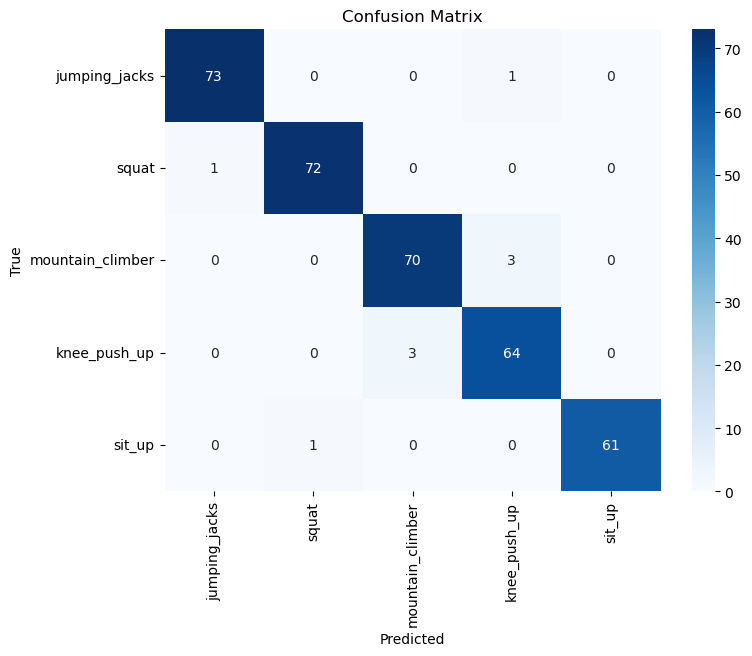

In [43]:
# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_map.keys(),
            yticklabels=label_map.keys())

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

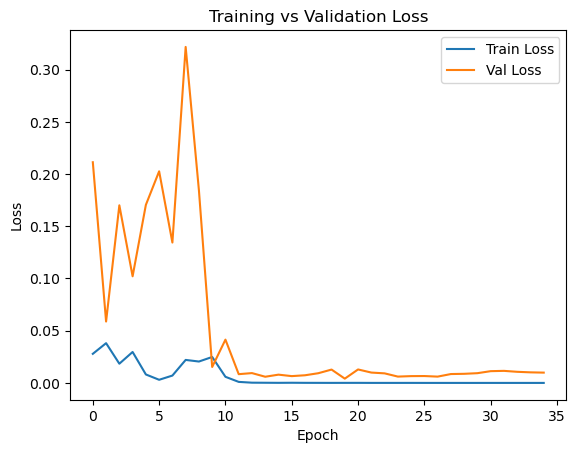

In [44]:
# Grafik Loss
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.show()